***Setting Up the values from Dataset***

In [37]:
import os, csv
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
results = {}

def load_csv(path):
    rows = []
    with open(path) as f:
        for line in f:
            parts = line.strip().split(",")
            try:
                rows.append([float(parts[0]), float(parts[1])])
            except (ValueError, IndexError):
                continue
    data = np.array(rows)
    return data[:, 0], data[:, 1]

def first_existing(*paths):
    for p in paths:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"none of {paths} found")

t, theta = load_csv("hw3.csv")
N = len(t)
print("N =", N, "| t from", t[0], "to", t[-1], "s | theta from", theta[0], "to", theta[-1], "rad")

N = 100 | t from 0.0 to 1200.0 s | theta from 0.08810099628046776 to 12.569817015620044 rad


***2.1 Maximum likelihood estimate***

Solution of 2.1(a) and 2.1(b) in the handwritten part of the Homework. 

***2.1(c)***

In [38]:
S_tt = np.sum(t**2)
S_ttheta = np.sum(t * theta)
w_mle = S_ttheta / S_tt

print(f"2.1(c) w_MLE   = {w_mle:.8f} rad/s   (period 2*pi/w = {2*np.pi/w_mle:.1f} s)")

2.1(c) w_MLE   = 0.01049340 rad/s   (period 2*pi/w = 598.8 s)


***2.1(d)***

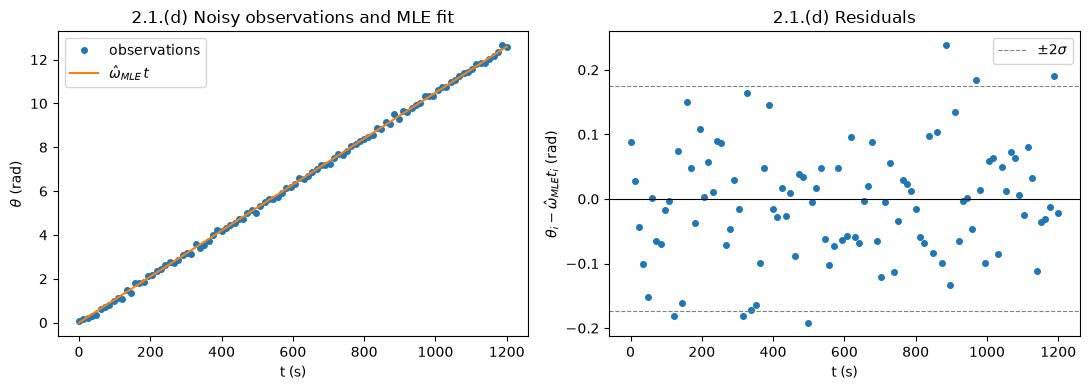

In [39]:
resid = theta - w_mle * t
sigma2 = np.sum(resid**2) / (N - 1)
sigma = np.sqrt(sigma2)
se_mle = sigma / np.sqrt(S_tt)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t, theta, "o", ms=4, label="observations")
ax[0].plot(t, w_mle * t, "-", label=r"$\hat\omega_{MLE}\,t$")
ax[0].set_xlabel("t (s)")
ax[0].set_ylabel(r"$\theta$ (rad)")
ax[0].set_title("2.1.(d) Noisy observations and MLE fit")
ax[0].legend()

ax[1].plot(t, resid, "o", ms=4)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].axhline(2 * sigma, color="gray", ls="--", lw=0.8, label=r"$\pm 2\sigma$")
ax[1].axhline(-2 * sigma, color="gray", ls="--", lw=0.8)
ax[1].set_xlabel("t (s)")
ax[1].set_ylabel(r"$\theta_i - \hat\omega_{MLE} t_i$ (rad)")
ax[1].set_title("2.1.(d) Residuals")
ax[1].legend()
fig.tight_layout()
fig.savefig("figures/fig_2_1_d.pdf")
plt.show()

***2.1(e)***

In [40]:
print(f"2.1(e) sigma^2 = {sigma2:.6f} rad^2   (sigma = {sigma:.5f} rad)")
print(f"       std. error of w_MLE = sigma/sqrt(sum t^2) = {se_mle:.3e} rad/s")

results["p1"] = dict(N=N, S_tt=S_tt, S_ttheta=S_ttheta, w_mle=w_mle, sigma2=sigma2,
                     sigma=sigma, se_mle=se_mle, period=2*np.pi/w_mle,
                     resid_mean=resid.mean(), resid_max=np.abs(resid).max())

2.1(e) sigma^2 = 0.007589 rad^2   (sigma = 0.08711 rad)
       std. error of w_MLE = sigma/sqrt(sum t^2) = 1.254e-05 rad/s


***2.2 Bayesian posterior (full dataset)***

In [41]:
def posterior(t, theta, sigma2, mu0, tau0_2):
    tauN_2 = 1.0 / (1.0 / tau0_2 + np.sum(t**2) / sigma2)
    muN = tauN_2 * (mu0 / tau0_2 + np.sum(t * theta) / sigma2)
    return muN, tauN_2

mu0, tau0_2 = 0.0, 100.0
muN, tauN_2 = posterior(t, theta, sigma2, mu0, tau0_2)
tauN = np.sqrt(tauN_2)

print(f"prior: mu0 = {mu0}, tau0^2 = {tau0_2}  -> prior precision {1/tau0_2:.2e}, data precision {S_tt/sigma2:.3e}")
print(f"2.2(b) posterior mean     mu_N    = {muN:.10f} rad/s")
print(f"       posterior variance tau_N^2 = {tauN_2:.6e} (rad/s)^2   (tau_N = {tauN:.6e})")
print(f"       95% credible interval      = [{muN-1.96*tauN:.7f}, {muN+1.96*tauN:.7f}] rad/s")
print(f"2.2(c) mu_N - w_MLE = {muN - w_mle:.3e} rad/s  (relative {(muN-w_mle)/w_mle:.2e})")
print(f"       tau_N / SE(w_MLE) = {tauN/se_mle:.12f}")

print("\n tau0^2      mu_N              tau_N")
sens = []
for tt in [1e-10, 1e-8, 1e-6, 1.0, 100.0]:
    m, v = posterior(t, theta, sigma2, 0.0, tt)
    sens.append((tt, m, np.sqrt(v)))
    print(f" {tt:8.0e}   {m:.10f}   {np.sqrt(v):.4e}")

results["p2"] = dict(mu0=mu0, tau0_2=tau0_2, muN=muN, tauN_2=tauN_2, tauN=tauN,
                     ci_lo=muN-1.96*tauN, ci_hi=muN+1.96*tauN,
                     diff=muN-w_mle, rel_diff=(muN-w_mle)/w_mle, ratio_se=tauN/se_mle,
                     prior_prec=1/tau0_2, data_prec=S_tt/sigma2,
                     sensitivity=[dict(tau0_2=a, muN=b, tauN=c) for a, b, c in sens])

prior: mu0 = 0.0, tau0^2 = 100.0  -> prior precision 1.00e-02, data precision 6.357e+09
2.2(b) posterior mean     mu_N    = 0.0104933979 rad/s
       posterior variance tau_N^2 = 1.573037e-10 (rad/s)^2   (tau_N = 1.254208e-05)
       95% credible interval      = [0.0104688, 0.0105180] rad/s
2.2(c) mu_N - w_MLE = -1.651e-14 rad/s  (relative -1.57e-12)
       tau_N / SE(w_MLE) = 0.999999999999

 tau0^2      mu_N              tau_N
    1e-10   0.0040782148   7.8189e-06
    1e-08   0.0103308892   1.2445e-05
    1e-06   0.0104917475   1.2541e-05
    1e+00   0.0104933979   1.2542e-05
    1e+02   0.0104933979   1.2542e-05


***2.3 Bayesian filtering***

***2.3(a)***

In [42]:
def filter_running_sums(t, theta, sigma2, mu0, tau0_2):
    K = len(t)
    mu, tau2 = np.empty(K), np.empty(K)
    Stt, Stth = 0.0, 0.0
    for k in range(K):           
        Stt += t[k] ** 2
        Stth += t[k] * theta[k]
        tau2[k] = 1.0 / (1.0 / tau0_2 + Stt / sigma2)
        mu[k] = tau2[k] * (mu0 / tau0_2 + Stth / sigma2)
    return mu, tau2

def filter_recursive(t, theta, sigma2, mu0, tau0_2):
    K = len(t)
    mu, tau2 = np.empty(K), np.empty(K)
    m, prec = mu0, 1.0 / tau0_2
    for k in range(K):
        prec_new = prec + t[k] ** 2 / sigma2
        m = (prec * m + t[k] * theta[k] / sigma2) / prec_new
        prec = prec_new
        mu[k], tau2[k] = m, 1.0 / prec
    return mu, tau2

mu_k, tau2_k = filter_running_sums(t, theta, sigma2, mu0, tau0_2)
mu_r, tau2_r = filter_recursive(t, theta, sigma2, mu0, tau0_2)
tau_k = np.sqrt(tau2_k)
k = np.arange(1, N + 1)

assert np.allclose(mu_k, mu_r, rtol=1e-12, atol=0) and np.allclose(tau2_k, tau2_r, rtol=1e-12)
assert np.isclose(mu_k[-1], muN, rtol=1e-12) and np.isclose(tau2_k[-1], tauN_2, rtol=1e-12)
print("running-sum and recursive filters agree; final posterior equals 2.2(b)")

for kk in [1, 2, 3, 5, 10, 25, 50, 100]:
    print(f"k = {kk:3d}: mu_k = {mu_k[kk-1]:.7f}   tau_k = {tau_k[kk-1]:.3e}   95% half-width = {1.96*tau_k[kk-1]:.3e}")

results["p3"] = dict(table=[dict(k=int(kk), mu=mu_k[kk-1], tau=tau_k[kk-1], half=1.96*tau_k[kk-1])
                            for kk in [1, 2, 3, 5, 10, 25, 50, 100]])

running-sum and recursive filters agree; final posterior equals 2.2(b)
k =   1: mu_k = 0.0000000   tau_k = 1.000e+01   95% half-width = 1.960e+01
k =   2: mu_k = 0.0127336   tau_k = 7.187e-03   95% half-width = 1.409e-02
k =   3: mu_k = 0.0095212   tau_k = 3.214e-03   95% half-width = 6.300e-03
k =   5: mu_k = 0.0078378   tau_k = 1.312e-03   95% half-width = 2.572e-03
k =  10: mu_k = 0.0099160   tau_k = 4.257e-04   95% half-width = 8.344e-04
k =  25: mu_k = 0.0105242   tau_k = 1.027e-04   95% half-width = 2.012e-04
k =  50: mu_k = 0.0104440   tau_k = 3.574e-05   95% half-width = 7.006e-05
k = 100: mu_k = 0.0104934   tau_k = 1.254e-05   95% half-width = 2.458e-05


***2.3(b)***

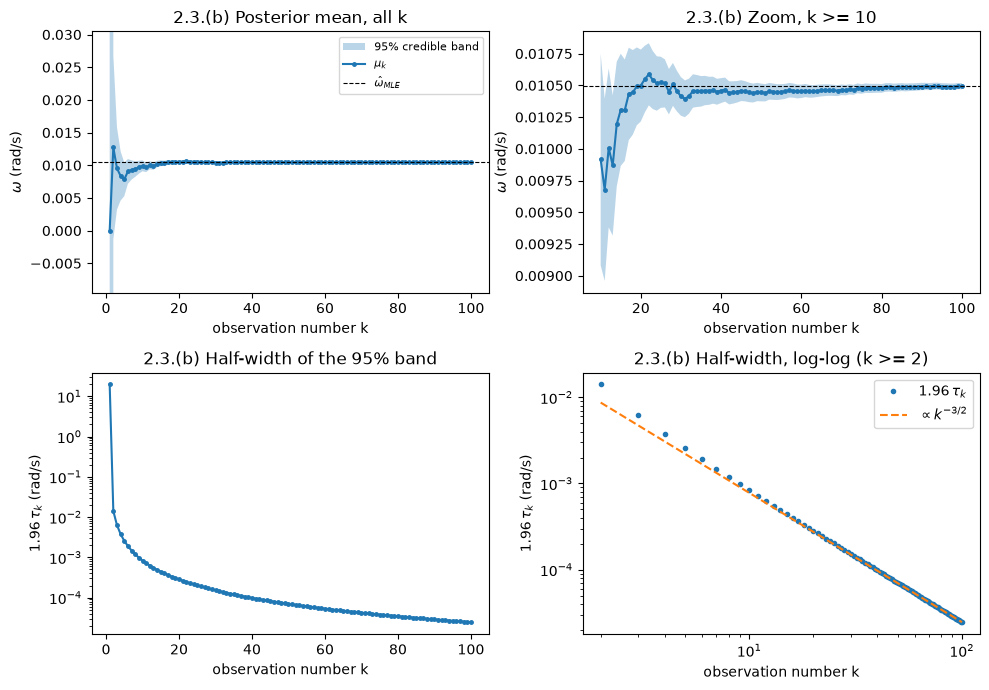

In [43]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
ax = ax.ravel()

ax[0].fill_between(k, mu_k - 1.96 * tau_k, mu_k + 1.96 * tau_k, alpha=0.3, label="95% credible band")
ax[0].plot(k, mu_k, "-o", ms=2.5, label=r"$\mu_k$")
ax[0].axhline(w_mle, color="k", ls="--", lw=0.8, label=r"$\hat\omega_{MLE}$")
ax[0].set_ylim(w_mle - 0.02, w_mle + 0.02)
ax[0].set_xlabel("observation number k")
ax[0].set_ylabel(r"$\omega$ (rad/s)")
ax[0].set_title("2.3.(b) Posterior mean, all k")
ax[0].legend(fontsize=8)

sel = k >= 10
ax[1].fill_between(k[sel], (mu_k - 1.96 * tau_k)[sel], (mu_k + 1.96 * tau_k)[sel], alpha=0.3)
ax[1].plot(k[sel], mu_k[sel], "-o", ms=2.5)
ax[1].axhline(w_mle, color="k", ls="--", lw=0.8)
ax[1].set_xlabel("observation number k")
ax[1].set_ylabel(r"$\omega$ (rad/s)")
ax[1].set_title("2.3.(b) Zoom, k >= 10")

ax[2].semilogy(k, 1.96 * tau_k, "-o", ms=2.5)
ax[2].set_xlabel("observation number k")
ax[2].set_ylabel(r"$1.96\,\tau_k$ (rad/s)")
ax[2].set_title("2.3.(b) Half-width of the 95% band")

ax[3].loglog(k[1:], 1.96 * tau_k[1:], "o", ms=3, label=r"$1.96\,\tau_k$")
ax[3].loglog(k[1:], 1.96 * tau_k[-1] * (k[1:] / N) ** -1.5, "--", label=r"$\propto k^{-3/2}$")
ax[3].set_xlabel("observation number k")
ax[3].set_ylabel(r"$1.96\,\tau_k$ (rad/s)")
ax[3].set_title("2.3.(b) Half-width, log-log (k >= 2)")
ax[3].legend()
fig.tight_layout()
fig.savefig("figures/fig_2_3_b.pdf")
plt.show()

***2.4 Information gain over time***

***2.4(a)***

In [44]:
mu_e, tau2_e = filter_running_sums(t, theta, sigma2, 0.0, 1.0)
H0 = 0.5 + 0.5 * np.log(2 * np.pi * 1.0)
H = np.concatenate([[H0], 0.5 + 0.5 * np.log(2 * np.pi * tau2_e)])   # H[0] = prior, H[k] after k obs
dH = np.diff(H)                                                        # dH[k-1] = H_k - H_{k-1}
kk = np.arange(0, N + 1)

print(f"H_0 (prior) = {H[0]:.4f} nats, H_1 = {H[1]:.4f}, H_2 = {H[2]:.4f}, H_N = {H[-1]:.4f}")
print("first few dH:", np.round(dH[:6], 4))
print(f"dH_N = {dH[-1]:.5f}  vs  -3/(2N) = {-1.5/N:.5f}")
print(f"total information gained H_0 - H_N = {H[0]-H[-1]:.3f} nats")

results["p4"] = dict(H0=H[0], H1=H[1], H2=H[2], H3=H[3], HN=H[-1], dH2=dH[1], dH3=dH[2],
                     dH10=dH[9], dH50=dH[49], dHN=dH[-1], total=H[0]-H[-1])

H_0 (prior) = 1.4189 nats, H_1 = 1.4189, H_2 = -3.5166, H_N = -9.8675
first few dH: [ 0.     -4.9355 -0.8047 -0.5148 -0.3811 -0.3031]
dH_N = -0.01515  vs  -3/(2N) = -0.01500
total information gained H_0 - H_N = 11.286 nats


***2.4(b)***

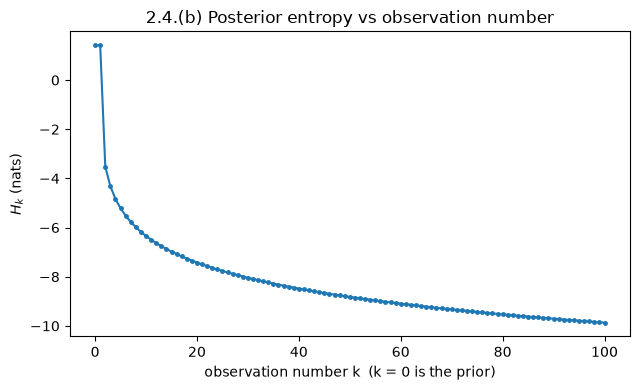

In [45]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(kk, H, "-o", ms=2.5)
ax.set_xlabel("observation number k  (k = 0 is the prior)")
ax.set_ylabel(r"$H_k$ (nats)")
ax.set_title("2.4.(b) Posterior entropy vs observation number")
fig.tight_layout()
fig.savefig("figures/fig_2_4_b.pdf")
plt.show()

***2.4(c)***

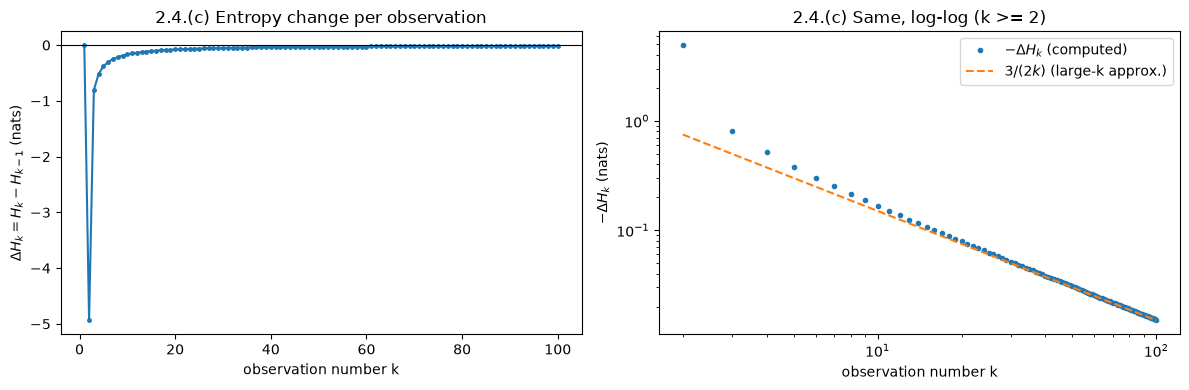

In [46]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k, dH, "-o", ms=2.5)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xlabel("observation number k")
ax[0].set_ylabel(r"$\Delta H_k = H_k - H_{k-1}$ (nats)")
ax[0].set_title("2.4.(c) Entropy change per observation")

ax[1].loglog(k[1:], -dH[1:], "o", ms=3, label=r"$-\Delta H_k$ (computed)")
ax[1].loglog(k[1:], 1.5 / k[1:], "--", label=r"$3/(2k)$ (large-k approx.)")
ax[1].set_xlabel("observation number k")
ax[1].set_ylabel(r"$-\Delta H_k$ (nats)")
ax[1].set_title("2.4.(c) Same, log-log (k >= 2)")
ax[1].legend()
fig.tight_layout()
fig.savefig("figures/fig_2_4_c.pdf")
plt.show()

Solution of 2.4(d) is in the handwritten part of the HW

***3. Star mass from Kepler's law***

In [47]:
G = 6.6743e-11          
r = 1.56479e11          
M_SUN = 1.989e30    

ts, ths = load_csv(first_existing("SolarData-Hw3.csv", "SolarData.csv"))
Ns = len(ts)
w_mle_s = np.sum(ts * ths) / np.sum(ts**2)
sigma2_s = np.sum((ths - w_mle_s * ts) ** 2) / (Ns - 1)
muN_s, tauN2_s = posterior(ts, ths, sigma2_s, 0.0, 1.0)
tauN_s = np.sqrt(tauN2_s)
print(f"N = {Ns} observations over {(ts[-1]-ts[0])/86400:.1f} days")
print(f"w_MLE = {w_mle_s:.5e} rad/s, sigma^2 = {sigma2_s:.4f} rad^2 (sigma = {np.sqrt(sigma2_s):.3f} rad)")
print(f"posterior: mu_N = {muN_s:.5e}, tau_N = {tauN_s:.3e} rad/s  ({100*tauN_s/muN_s:.2f}%)")
print(f"implied period = {2*np.pi/muN_s/86400:.1f} days")

rng = np.random.default_rng(602)
n_samp = 1_000_000
w_samp = rng.normal(muN_s, tauN_s, n_samp)
M_samp = w_samp**2 * r**3 / G

q = np.percentile(M_samp, [2.5, 16, 50, 84, 97.5])
M_med, M_mean, M_std = q[2], M_samp.mean(), M_samp.std()
M_plugin = muN_s**2 * r**3 / G
M_delta = 2 * M_plugin * tauN_s / muN_s      

w_t = muN_s + tauN_s * rng.standard_t(Ns - 1, n_samp)
qt = np.percentile(w_t**2 * r**3 / G, [2.5, 16, 50, 84, 97.5])

print(f"\nM median = {M_med:.4e} kg  ({M_med/M_SUN:.3f} M_sun)")
print(f"M mean   = {M_mean:.4e} kg,  std = {M_std:.3e} kg  ({100*M_std/M_med:.1f}%)")
print(f"68% interval [{q[1]:.3e}, {q[3]:.3e}],  95% interval [{q[0]:.3e}, {q[4]:.3e}] kg")
print(f"plug-in M(mu_N) = {M_plugin:.4e}, delta-method sigma_M = {M_delta:.3e}")
print(f"Student-t check: 68% [{qt[1]:.3e}, {qt[3]:.3e}], 95% [{qt[0]:.3e}, {qt[4]:.3e}] kg")

results["p5"] = dict(N=Ns, days=(ts[-1]-ts[0])/86400, w_mle=w_mle_s, sigma2=sigma2_s,
                     sigma=np.sqrt(sigma2_s), muN=muN_s, tauN=tauN_s, rel_tau=tauN_s/muN_s,
                     period_days=2*np.pi/muN_s/86400, M_med=M_med, M_mean=M_mean, M_std=M_std,
                     q=list(q), M_plugin=M_plugin, M_delta=M_delta, qt=list(qt),
                     M_med_sun=M_med/M_SUN, M_std_sun=M_std/M_SUN, G=G, r=r, n_samp=n_samp)

N = 12 observations over 365.0 days
w_MLE = 2.00331e-07 rad/s, sigma^2 = 0.3696 rad^2 (sigma = 0.608 rad)
posterior: mu_N = 2.00331e-07, tau_N = 9.427e-09 rad/s  (4.71%)
implied period = 363.0 days

M median = 2.3043e+30 kg  (1.159 M_sun)
M mean   = 2.3092e+30 kg,  std = 2.169e+29 kg  (9.4%)
68% interval [2.093e+30, 2.525e+30],  95% interval [1.898e+30, 2.748e+30] kg
plug-in M(mu_N) = 2.3039e+30, delta-method sigma_M = 2.168e+29
Student-t check: 68% [2.083e+30, 2.535e+30], 95% [1.851e+30, 2.805e+30] kg


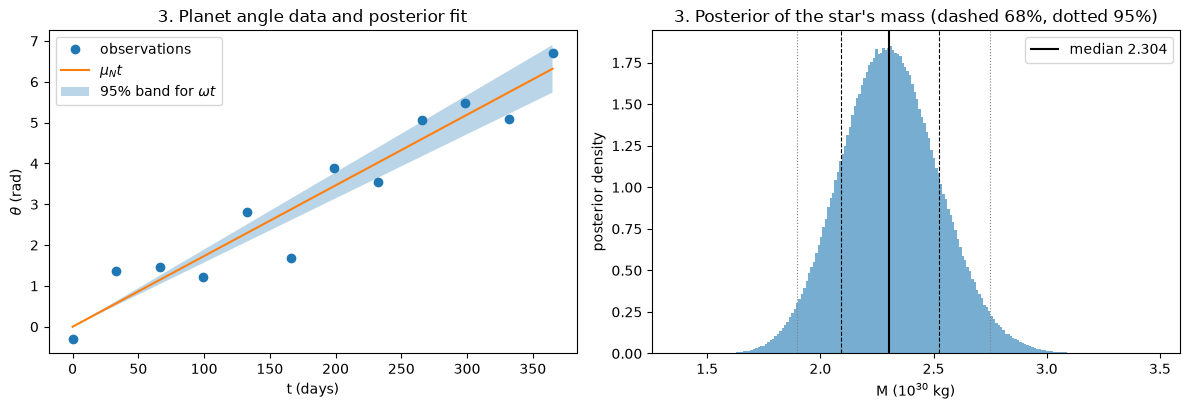

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
tt = np.linspace(0, ts.max(), 200)
day = 86400.0
ax[0].plot(ts / day, ths, "o", label="observations")
ax[0].plot(tt / day, muN_s * tt, "-", label=r"$\mu_N t$")
ax[0].fill_between(tt / day, (muN_s - 1.96 * tauN_s) * tt, (muN_s + 1.96 * tauN_s) * tt,
                   alpha=0.3, label=r"95% band for $\omega t$")
ax[0].set_xlabel("t (days)")
ax[0].set_ylabel(r"$\theta$ (rad)")
ax[0].set_title("3. Planet angle data and posterior fit")
ax[0].legend()

ax[1].hist(M_samp / 1e30, bins=200, density=True, alpha=0.6)
ax[1].axvline(M_med / 1e30, color="k", label=f"median {M_med/1e30:.3f}")
for v in (q[1], q[3]):
    ax[1].axvline(v / 1e30, color="k", ls="--", lw=0.8)
for v in (q[0], q[4]):
    ax[1].axvline(v / 1e30, color="gray", ls=":", lw=0.8)
ax[1].set_xlabel(r"M ($10^{30}$ kg)")
ax[1].set_ylabel("posterior density")
ax[1].set_title("3. Posterior of the star's mass (dashed 68%, dotted 95%)")
ax[1].legend()
fig.tight_layout()
fig.savefig("figures/fig_3.pdf")
plt.show()

In [49]:
def to_py(o):
    if isinstance(o, dict):
        return {k: to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o

def flatten(d, prefix=""):
    rows = []
    for k, v in d.items():
        name = f"{prefix}{k}"
        if isinstance(v, dict):
            rows += flatten(v, name + ".")
        elif isinstance(v, list):
            for i, item in enumerate(v):
                if isinstance(item, dict):
                    rows += flatten(item, f"{name}[{i}].")
                else:
                    rows.append((f"{name}[{i}]", item))
        else:
            rows.append((name, v))
    return rows

with open("results.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["quantity", "value"])
    writer.writerows(flatten(to_py(results)))
print("wrote results.csv")

wrote results.csv
